# DSCI 552 Homework 6
Ananth Dhananjay

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier

## 1. Tree-Based Methods
### (a)

In [2]:
train = pd.read_csv('aps_failure_training_set.csv', skiprows=20, na_values='na')
test = pd.read_csv('aps_failure_test_set.csv', skiprows=20, na_values='na')
print(train.shape, test.shape)

(60000, 171) (16000, 171)


### (b) i.

Common ways to deal with missing values:
- Drop the rows or columns that have them. Here 99% of rows have at least one missing value, so that would throw out almost everything.
- Fill each column with its mean or median [1].
- KNN imputation, which fills a value using the most similar rows [2].
- MICE, which regresses each feature on the others and repeats [3].
- missForest, which is like MICE but uses random forests [4].
- Leave them missing and use a model that handles NaN, like XGBoost [5].

I used median imputation since the features are very skewed. Per footnote 1, the test set is filled with its own medians.

[1] Little and Rubin, Statistical Analysis with Missing Data, 3rd ed., 2019<br>
[2] Troyanskaya et al., Bioinformatics 17(6), 2001<br>
[3] van Buuren and Groothuis-Oudshoorn, Journal of Statistical Software 45(3), 2011<br>
[4] Stekhoven and Buhlmann, Bioinformatics 28(1), 2012<br>
[5] Chen and Guestrin, XGBoost: A Scalable Tree Boosting System, KDD 2016

In [3]:
X_train = train.drop(columns='class')
X_test = test.drop(columns='class')
y_train = (train['class'] == 'pos').astype(int)
y_test = (test['class'] == 'pos').astype(int)

print('rows with at least one missing value:', round(X_train.isna().any(axis=1).mean(), 4))
print(X_train.isna().mean().sort_values(ascending=False).head(5).round(3))

X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_test.median())
print('missing after imputation:', X_train.isna().sum().sum(), X_test.isna().sum().sum())

rows with at least one missing value: 0.9902
br_000    0.821
bq_000    0.812
bp_000    0.796
bo_000    0.772
ab_000    0.772
dtype: float64


missing after imputation: 0 0


### (b) ii.

In [4]:
cv = (X_train.std() / X_train.mean()).sort_values(ascending=False)
cv_df = cv.round(3).reset_index()
cv_df.columns = ['feature', 'CV']
print(pd.concat([cv_df.iloc[i*43:(i+1)*43].reset_index(drop=True) for i in range(4)], axis=1).to_string(index=False))

feature      CV feature     CV feature    CV feature    CV
 cf_000 244.888  az_007 16.229  cs_004 4.685  ee_003 2.573
 co_000 244.507  cl_000 14.971  eb_000 4.540  cc_000 2.524
 ad_000 244.323  cz_000 14.506  de_000 4.528  bx_000 2.512
 cs_009 237.931  cp_000 13.933  cn_003 4.192  cs_005 2.510
 dh_000 123.216  az_002 13.272  cg_000 4.025  aa_000 2.451
 dj_000 117.494  ay_005 12.525  ax_000 4.019  by_000 2.450
 ag_000  92.918  di_000 11.826  ay_008 3.816  bt_000 2.448
 as_000  87.332  ar_000 11.354  cs_001 3.663  bb_000 2.405
 ay_009  84.734  cn_001 11.263  dv_000 3.587  bu_000 2.405
 ak_000  80.425  cj_000 11.070  bj_000 3.576  bv_000 2.405
 az_009  77.839  ab_000 10.383  ay_007 3.314  cq_000 2.405
 ch_000  77.454  cn_008  9.734  ee_000 3.300  ci_000 2.400
 au_000  68.883  ba_009  9.430  ee_001 3.281  ed_000 2.394
 cr_000  58.078  az_000  9.406  ee_008 3.259  ag_006 2.357
 ay_001  52.825  al_000  9.173  ee_006 3.219  cn_005 2.345
 df_000  52.293    am_0  9.155  cn_006 3.163  ds_000 2.3

### (b) iii.

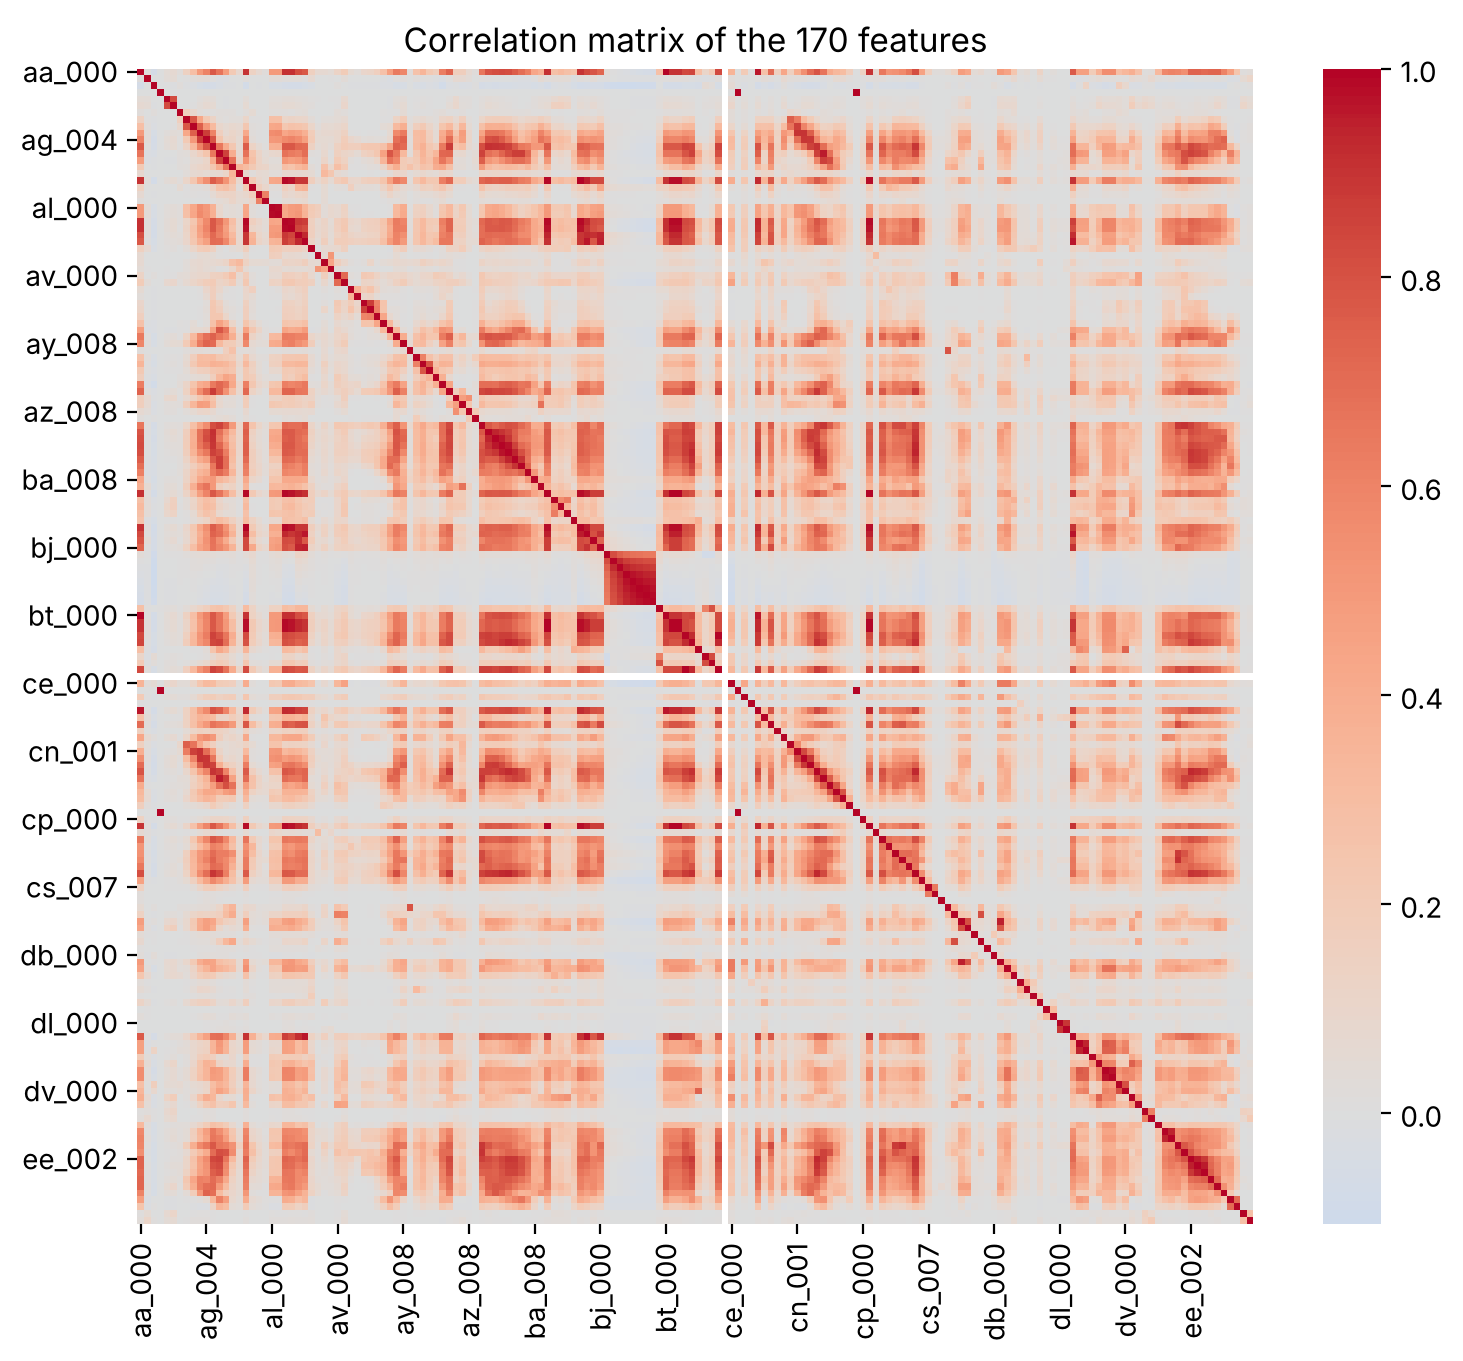

In [5]:
plt.figure(figsize=(9, 7.5))
sns.heatmap(X_train.corr(), cmap='coolwarm', center=0, xticklabels=10, yticklabels=10)
plt.title('Correlation matrix of the 170 features')
plt.show()

cd_000 is constant, so its row and column are blank. Most correlations are positive, and some groups of features with the same prefix are strongly correlated with each other.

### (b) iv.

In [6]:
top = cv.index[:int(np.floor(np.sqrt(170)))].tolist()
print(top)

['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


floor(sqrt(170)) = 13. I plotted log(1 + x) because the values are very skewed, and used all positives plus 4,000 random negatives for the scatter plots.

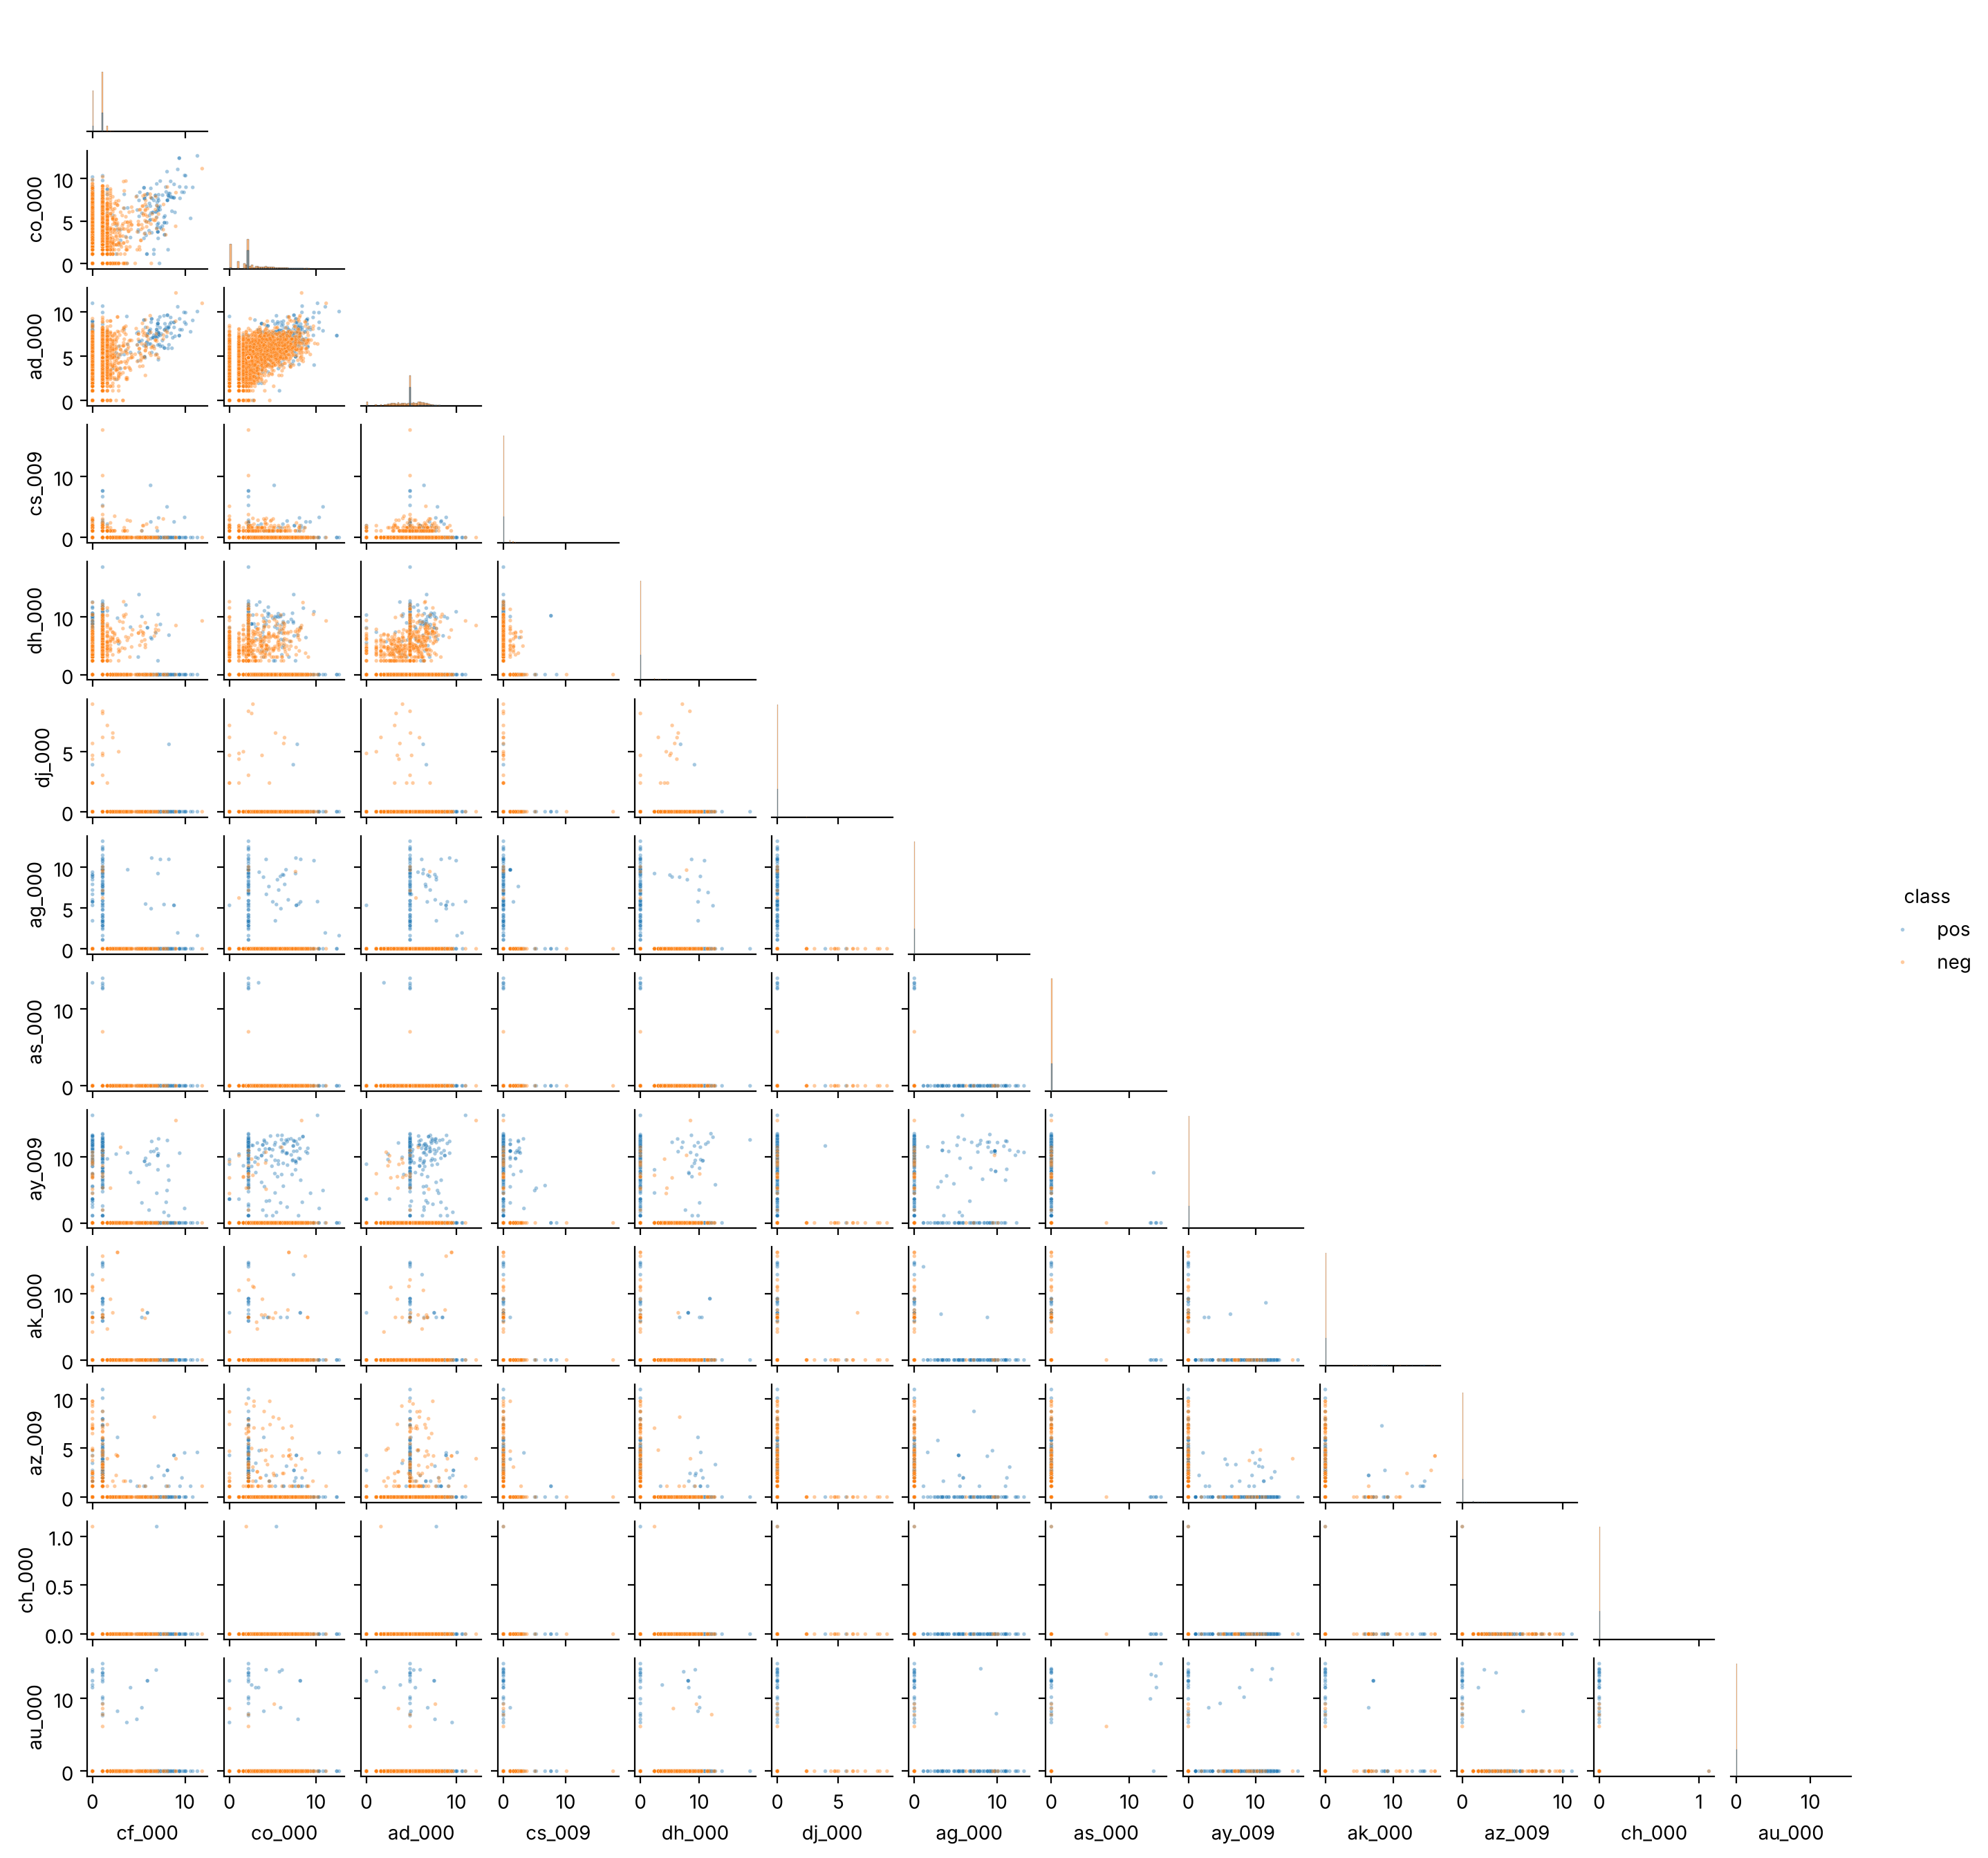

In [7]:
plot_df = np.log1p(X_train[top])
plot_df['class'] = train['class']
sample = pd.concat([plot_df[plot_df['class'] == 'pos'],
    plot_df[plot_df['class'] == 'neg'].sample(4000, random_state=0)])
sns.pairplot(sample, vars=top, hue='class', corner=True, diag_kind='hist', height=1.05, plot_kws={'s': 4, 'alpha': 0.4})
plt.show()

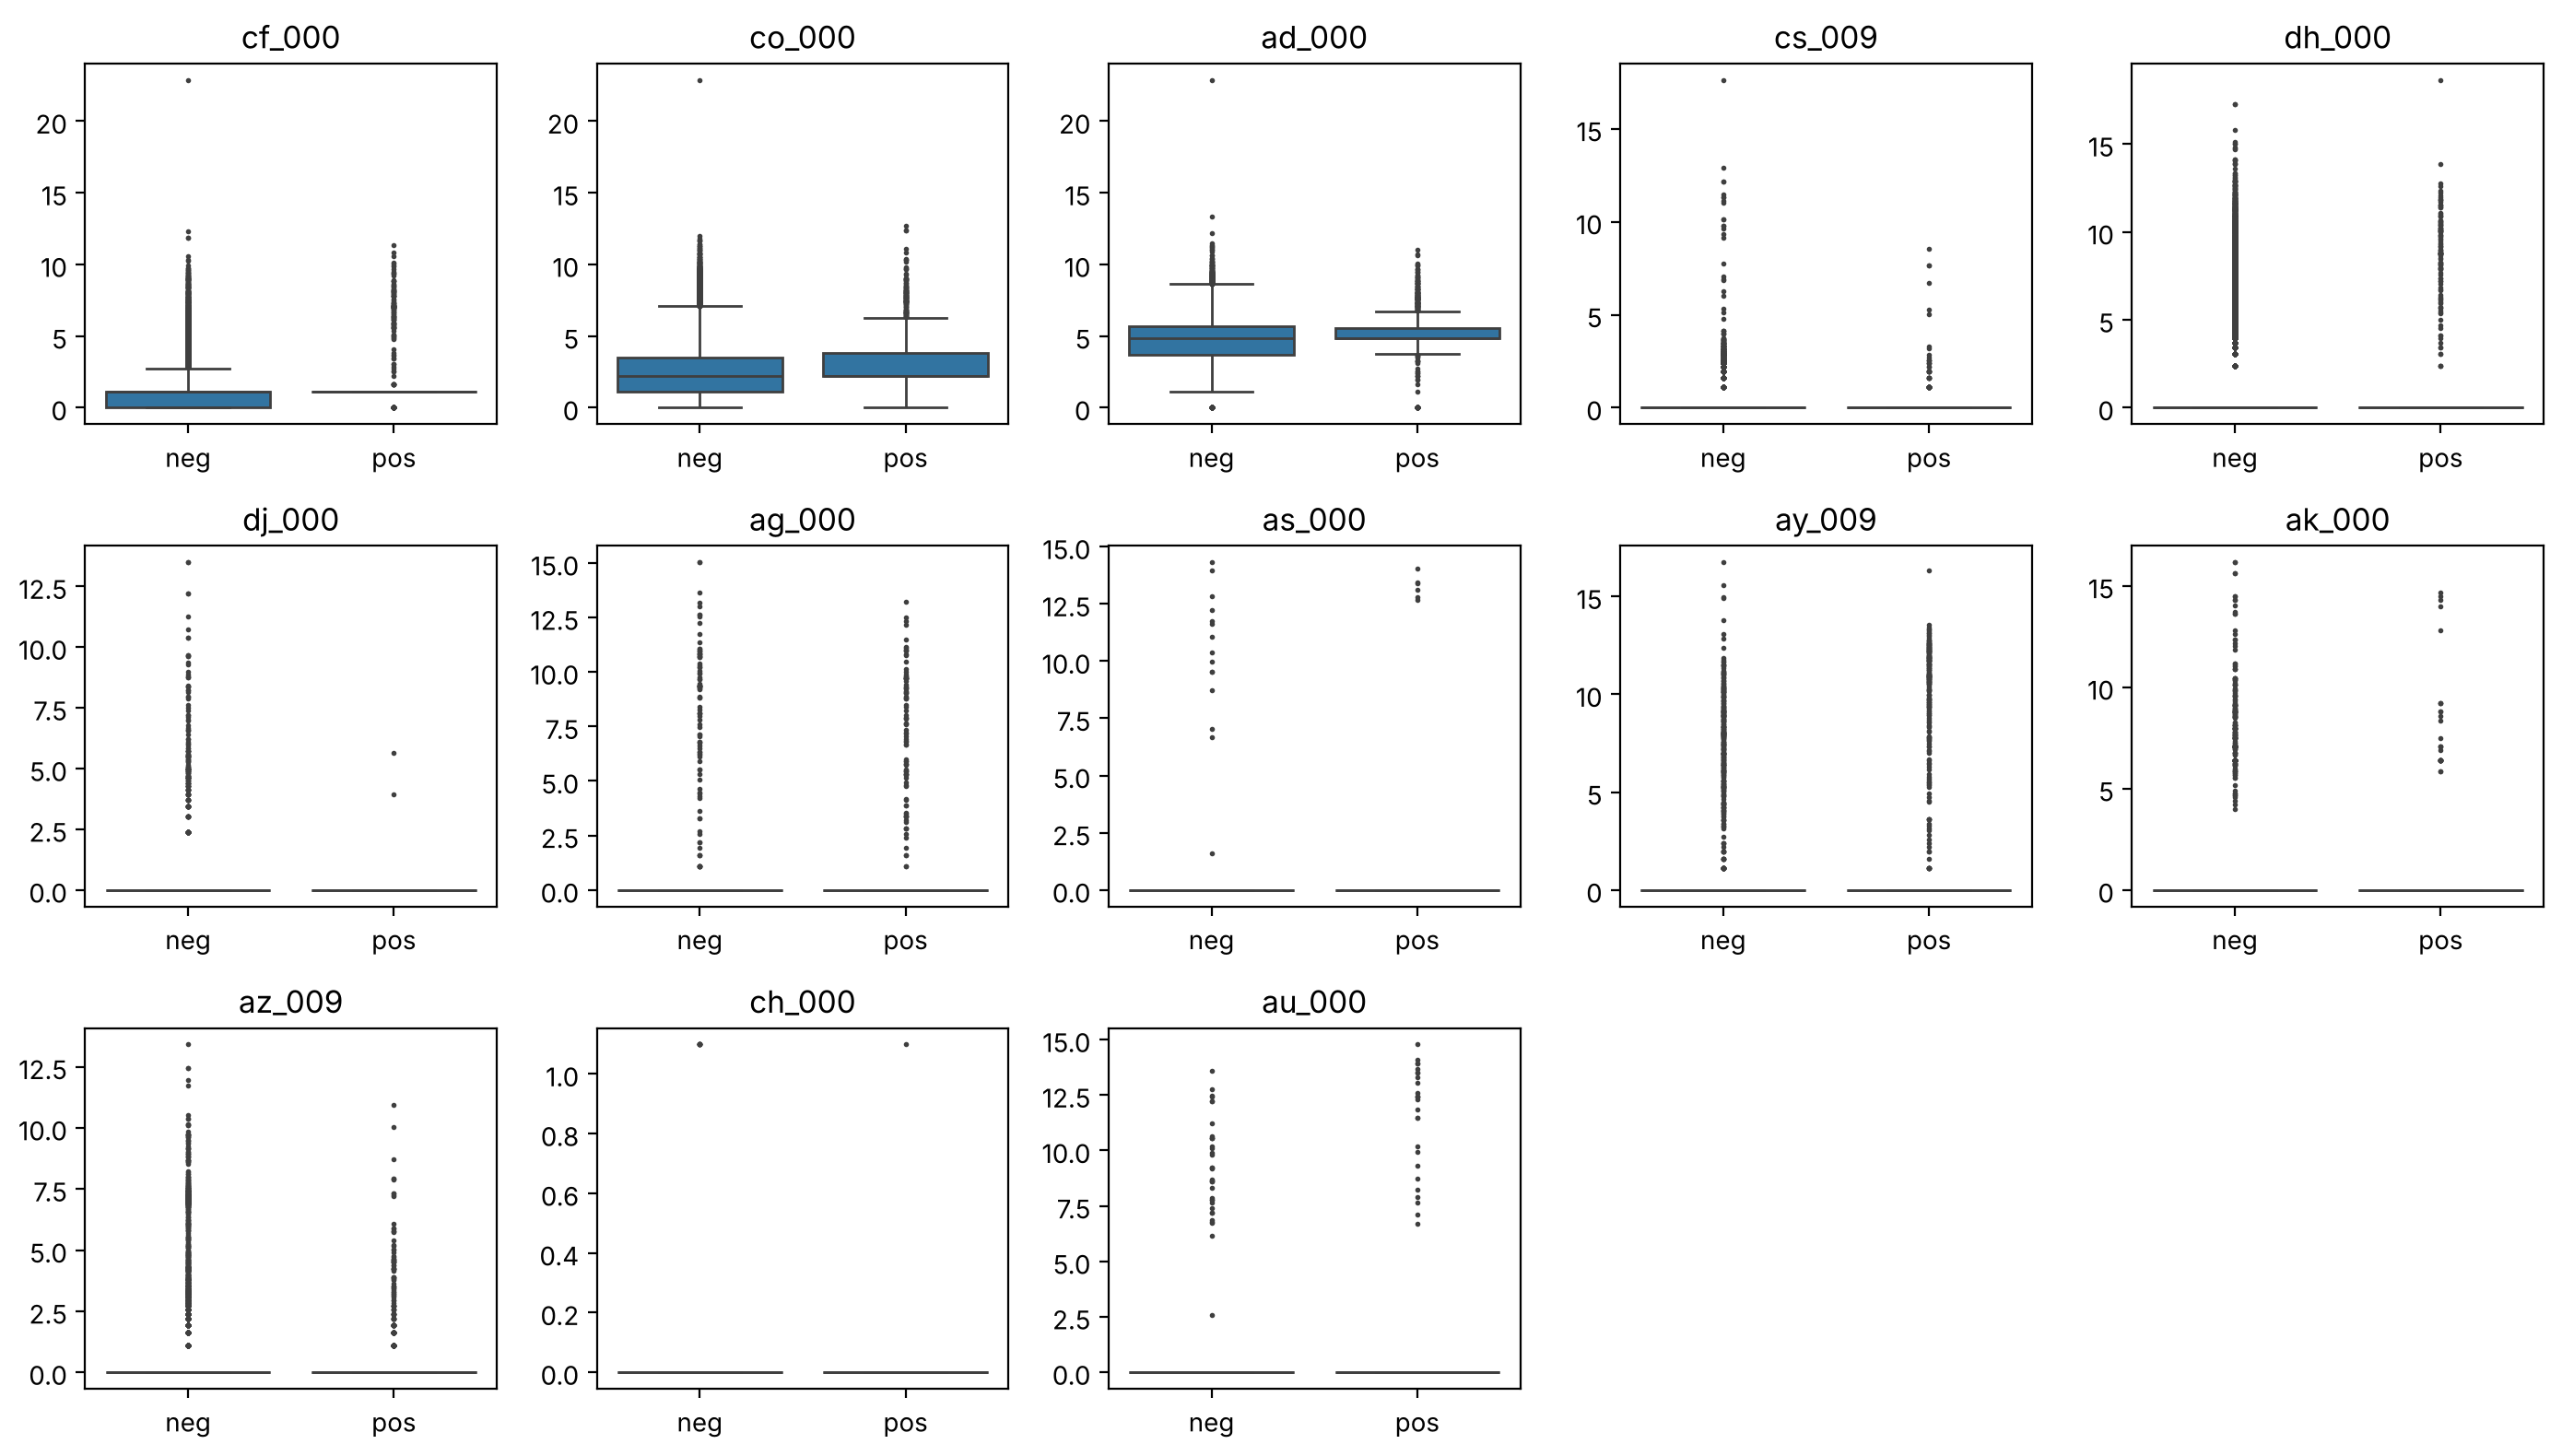

In [8]:
fig, axes = plt.subplots(3, 5, figsize=(14, 8))
for ax, f in zip(axes.flat, top):
    sns.boxplot(x=plot_df['class'], y=plot_df[f], ax=ax, fliersize=1)
    ax.set_title(f)
    ax.set_xlabel('')
    ax.set_ylabel('')
for ax in axes.flat[len(top):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

Not really. Some features look different between classes. For example ay_009, ag_000 and az_009 are nonzero more often for positives, and co_000 and ad_000 sit a bit higher for positives. Others like dh_000 and cs_009 look the same. But the classes overlap a lot and each plot only looks at one or two features, so this doesn't tell us whether a feature is significant. That would need a model or a test.

### (b) v.

In [9]:
print(train['class'].value_counts())
print(test['class'].value_counts())

class
neg    59000
pos     1000
Name: count, dtype: int64
class
neg    15625
pos      375
Name: count, dtype: int64


1,000 positive and 59,000 negative in training, 375 and 15,625 in test. Yes, it's very imbalanced. Predicting negative for everything would already get about 98% accuracy.

### (c)

In [10]:
def evaluate(model, X, y, label):
    prob = model.predict_proba(X)[:, 1]
    pred = (prob > 0.5).astype(int)
    cm = pd.DataFrame(confusion_matrix(y, pred), index=['true neg', 'true pos'], columns=['pred neg', 'pred pos'])
    print(label)
    print(cm)
    print('AUC:', round(roc_auc_score(y, prob), 4), ' misclassification:', round((pred != y).mean(), 4))
    print()
    fpr, tpr, _ = roc_curve(y, prob)
    plt.plot(fpr, tpr, label=label)
    return (pred != y).mean()

def roc_plot(model, title):
    plt.figure(figsize=(5, 4))
    evaluate(model, X_train, y_train, 'train')
    test_err = evaluate(model, X_test, y_test, 'test')
    plt.plot([0, 1], [0, 1], 'k--', lw=0.8)
    plt.xlabel('false positive rate')
    plt.ylabel('true positive rate')
    plt.title(title)
    plt.legend()
    plt.show()
    return test_err

train
          pred neg  pred pos
true neg     59000         0
true pos         0      1000
AUC: 1.0  misclassification: 0.0



test
          pred neg  pred pos
true neg     15606        19
true pos       101       274
AUC: 0.9944  misclassification: 0.0075



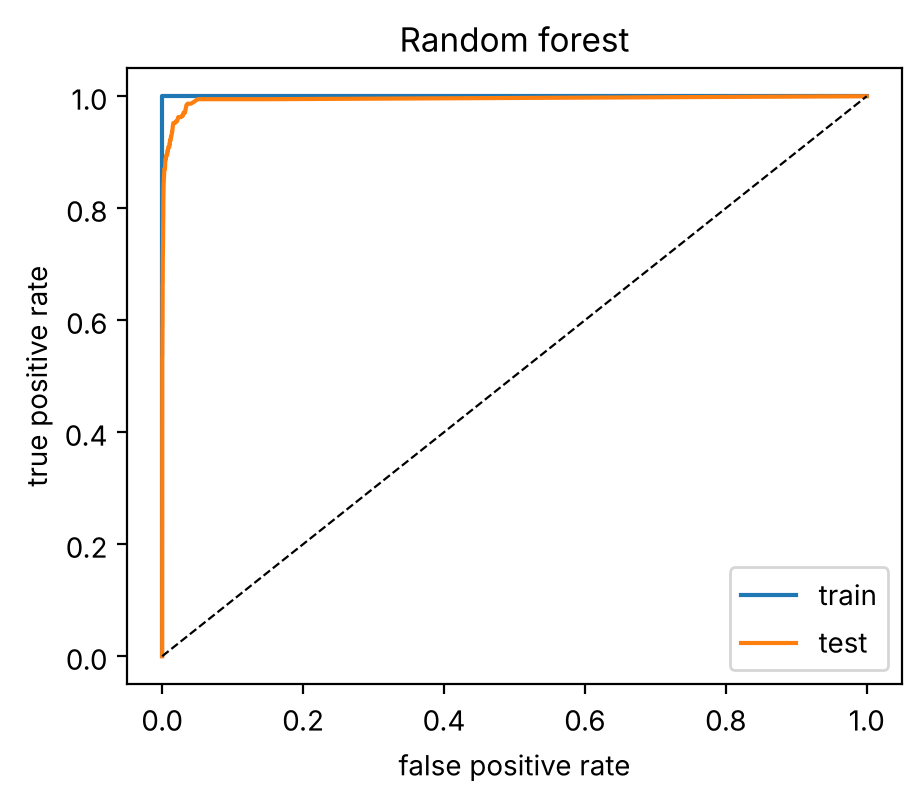

OOB error: 0.0058
test error: 0.0075


In [11]:
rf = RandomForestClassifier(n_estimators=300, oob_score=True, n_jobs=-1, random_state=0)
rf.fit(X_train, y_train)
rf_test_err = roc_plot(rf, 'Random forest')
print('OOB error:', round(1 - rf.oob_score_, 4))
print('test error:', round(rf_test_err, 4))

The training set is fit perfectly, which is expected with fully grown trees. Test error is 0.0075 and the OOB error is 0.0058, so OOB is close to the test error. But the forest misses 101 of the 375 positive trucks in the test set.

### (d)

The two common fixes from Chen, Liaw and Breiman [6] are a weighted random forest, where the minority class gets a higher weight, and a balanced random forest, where each tree is grown on a sample with equal numbers of each class. Resampling the data before training (e.g. SMOTE [7]) is another option. I used the balanced random forest from imbalanced-learn.

[6] Chen, Liaw and Breiman, Using Random Forest to Learn Imbalanced Data, UC Berkeley Tech Report 666, 2004<br>
[7] Chawla et al., SMOTE, Journal of Artificial Intelligence Research 16, 2002

train
          pred neg  pred pos
true neg     56451      2549
true pos         0      1000
AUC: 0.9982  misclassification: 0.0425



test
          pred neg  pred pos
true neg     14981       644
true pos         7       368
AUC: 0.9929  misclassification: 0.0407



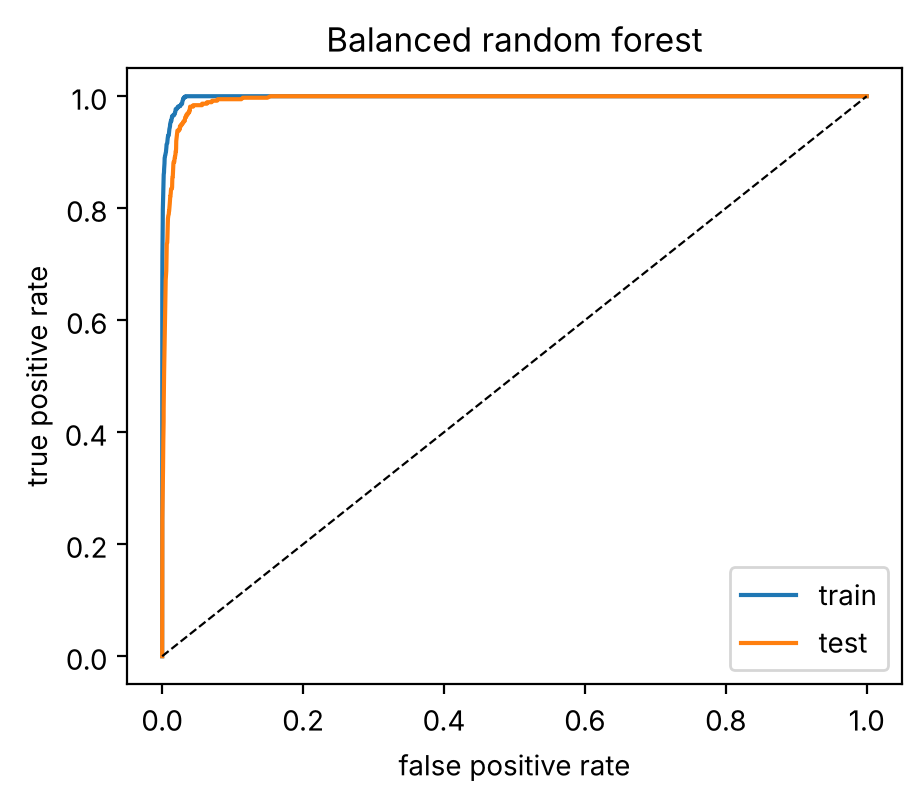

In [12]:
brf = BalancedRandomForestClassifier(n_estimators=300, sampling_strategy='all', replacement=True,
    bootstrap=False, n_jobs=-1, random_state=0)
brf.fit(X_train, y_train)
brf_test_err = roc_plot(brf, 'Balanced random forest')

imbalanced-learn doesn't give a usable OOB score for this setup, so I computed it from the trees that didn't see each row.

In [13]:
n = len(y_train)
votes = np.zeros(n)
counts = np.zeros(n)
for sampler, tree in zip(brf.samplers_, brf.estimators_):
    oob = np.setdiff1d(np.arange(n), sampler.sample_indices_)
    votes[oob] += tree.predict_proba(X_train.values[oob])[:, 1]
    counts[oob] += 1
oob_err = ((votes / counts > 0.5) != y_train).mean()
print('OOB error:', round(oob_err, 4))
print('test error:', round(brf_test_err, 4))

OOB error: 0.0439
test error: 0.0407


Missed positives on the test set drop from 101 to 7, but false positives go from 19 to 644, so overall test error goes up from 0.0075 to 0.0407. AUC is about the same (0.9929 vs 0.9944). OOB error (0.0439) is still close to the test error. So balancing doesn't make the model better overall; it catches more failures at the cost of more false alarms.

### (e)

I used XGBoost with the logistic objective and tuned reg_alpha (the L1 penalty) with 5-fold CV. Note that XGBoost's trees still split on one feature at a time.

In [14]:
alphas = [0, 0.01, 0.1, 1, 10, 100]
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
xgb = XGBClassifier(n_estimators=200, learning_rate=0.1, tree_method='hist', random_state=0)
grid = GridSearchCV(xgb, {'reg_alpha': alphas}, cv=folds, scoring={'auc': 'roc_auc', 'acc': 'accuracy'}, refit='auc')
grid.fit(X_train, y_train)

res = pd.DataFrame({'alpha': alphas, 'CV AUC': grid.cv_results_['mean_test_auc'],
    'CV error': 1 - grid.cv_results_['mean_test_acc']})
print(res.round(5).to_string(index=False))
print('best alpha:', grid.best_params_['reg_alpha'])

 alpha  CV AUC  CV error
  0.00 0.98971   0.00525
  0.01 0.98941   0.00532
  0.10 0.99012   0.00522
  1.00 0.98995   0.00542
 10.00 0.98911   0.00668
100.00 0.98239   0.01165
best alpha: 0.1


train
          pred neg  pred pos
true neg     59000         0
true pos         2       998
AUC: 1.0  misclassification: 0.0



test
          pred neg  pred pos
true neg     15608        17
true pos        83       292
AUC: 0.995  misclassification: 0.0062



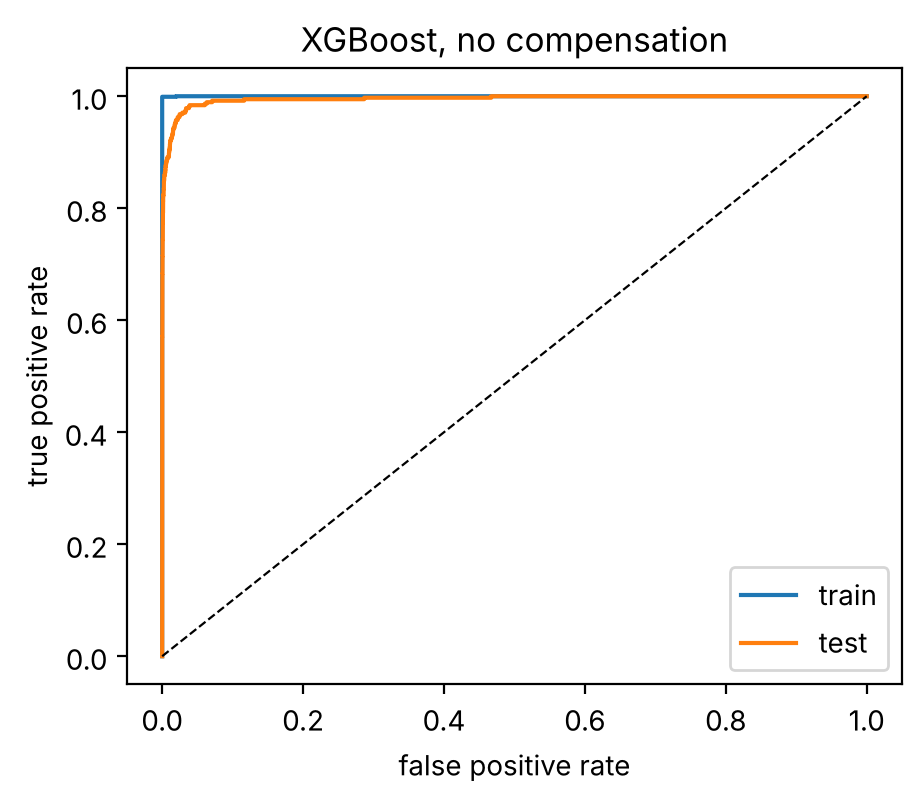

5-fold CV error: 0.0052
test error: 0.0062


In [15]:
xgb_test_err = roc_plot(grid.best_estimator_, 'XGBoost, no compensation')
print('5-fold CV error:', round(1 - grid.cv_results_['mean_test_acc'][grid.best_index_], 4))
print('test error:', round(xgb_test_err, 4))

The best alpha was 0.1. The 5-fold CV error is 0.0052 and the test error is 0.0062, so CV is a little optimistic, partly because the same folds were used to pick alpha. On test it does a bit better than the random forest in 1(c) (83 missed positives vs 101).

### (f)

SMOTE has to be done inside each CV fold, only on the training part. If it's done before splitting, synthetic points made from validation rows leak into training and the CV error looks too good. The imbalanced-learn Pipeline handles this.

In [16]:
pipe = Pipeline([('smote', SMOTE(random_state=0)),
    ('xgb', XGBClassifier(n_estimators=200, learning_rate=0.1, tree_method='hist', random_state=0))])
grid_s = GridSearchCV(pipe, {'xgb__reg_alpha': alphas}, cv=folds, scoring={'auc': 'roc_auc', 'acc': 'accuracy'}, refit='auc')
grid_s.fit(X_train, y_train)

res_s = pd.DataFrame({'alpha': alphas, 'CV AUC': grid_s.cv_results_['mean_test_auc'],
    'CV error': 1 - grid_s.cv_results_['mean_test_acc']})
print(res_s.round(5).to_string(index=False))
print('best alpha:', grid_s.best_params_['xgb__reg_alpha'])

 alpha  CV AUC  CV error
  0.00 0.98955   0.00672
  0.01 0.98960   0.00663
  0.10 0.98935   0.00653
  1.00 0.98935   0.00660
 10.00 0.98891   0.00787
100.00 0.98471   0.01828
best alpha: 0.01


train
          pred neg  pred pos
true neg     58996         4
true pos         9       991
AUC: 1.0  misclassification: 0.0002



test
          pred neg  pred pos
true neg     15535        90
true pos        49       326
AUC: 0.995  misclassification: 0.0087



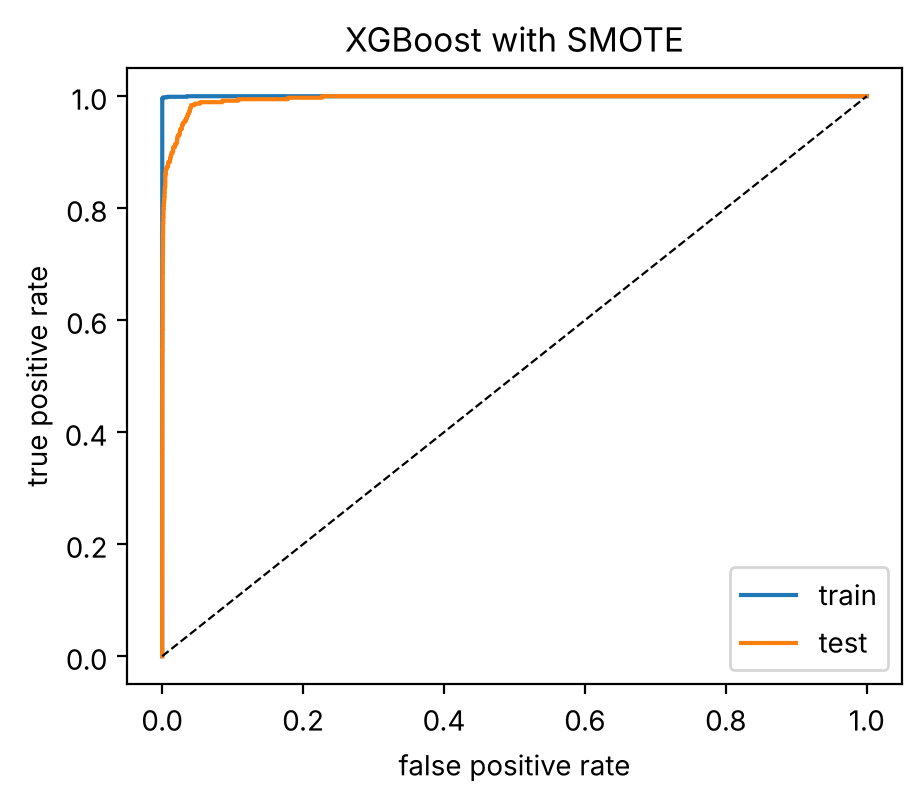

5-fold CV error: 0.0066
test error: 0.0087


In [17]:
smote_test_err = roc_plot(grid_s.best_estimator_, 'XGBoost with SMOTE')
print('5-fold CV error:', round(1 - grid_s.cv_results_['mean_test_acc'][grid_s.best_index_], 4))
print('test error:', round(smote_test_err, 4))

With SMOTE, missed positives go from 83 to 49 but false positives go from 17 to 90, so test error goes up from 0.0062 to 0.0087. AUC is the same (0.995). CV error (0.0066) is again a little below test error. Like in 1(d), SMOTE trades more false alarms for catching more failures, but the shift is smaller than with the balanced random forest.

## 2. ISLR 6.6.3

(a) iv. Training RSS steadily decreases. At s = 0 every β is 0. As s grows the constraint loosens and the fit can only get closer to least squares, so training RSS can't go up.

(b) ii. Test RSS decreases at first, then increases (U shape). Small s gives a model that is too simple (high bias); large s approaches least squares and starts to overfit.

(c) iii. Variance steadily increases. At s = 0 the model is a constant with zero variance, and more freedom makes the coefficients depend more on the particular training set.

(d) iv. Squared bias steadily decreases, because the model gets more flexible.

(e) v. Irreducible error stays constant. Var(ε) doesn't depend on the model.

## 3. ISLR 6.6.5

Setup: let x11 = x12 = a. Then x21 = x22 = -a (from x11 + x21 = 0 and x12 + x22 = 0), and y2 = -y1. The intercept is 0.

(a) Ridge minimizes

$$(y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(\beta_1^2 + \beta_2^2)$$

Substituting, this is $2(y_1 - a(\beta_1 + \beta_2))^2 + \lambda(\beta_1^2 + \beta_2^2)$.

(b) Setting the partial derivatives to 0:

$$-4a(y_1 - a(\beta_1 + \beta_2)) + 2\lambda\beta_1 = 0, \qquad -4a(y_1 - a(\beta_1 + \beta_2)) + 2\lambda\beta_2 = 0$$

The first term is the same in both equations, so subtracting gives $2\lambda(\beta_1 - \beta_2) = 0$. With λ > 0, β1 = β2. The objective is strictly convex for λ > 0, so this is the unique minimum.

(c) Lasso minimizes

$$2(y_1 - a(\beta_1 + \beta_2))^2 + \lambda(|\beta_1| + |\beta_2|)$$

(d) The RSS part only depends on the sum β1 + β2. For a fixed sum c, |β1| + |β2| ≥ |c|, with equality whenever β1 and β2 both have the same sign as c. So if a solution has β1 + β2 = c, every pair with β1 + β2 = c and both coefficients of the sign of c gives the same objective value. The lasso solution is not unique: it is the whole segment from (c, 0) to (0, c).

In the constraint form |β1| + |β2| ≤ s, the RSS contours are the lines β1 + β2 = constant, which are parallel to the edges of the diamond. When the contour touches the diamond it touches a whole edge, for example β1 + β2 = s with β1, β2 ≥ 0 (when y1/a > s).

## 4. ISLR 8.4.5

In [18]:
p = np.array([0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75])
print('votes for red:', (p > 0.5).sum(), 'of', len(p))
print('average probability:', p.mean())

votes for red: 6 of 10
average probability: 0.45


Majority vote: 6 of the 10 estimates are above 0.5, so the prediction is **Red**.

Average probability: 0.45 < 0.5, so the prediction is **Green**.

## 5. ISLR 9.7.3

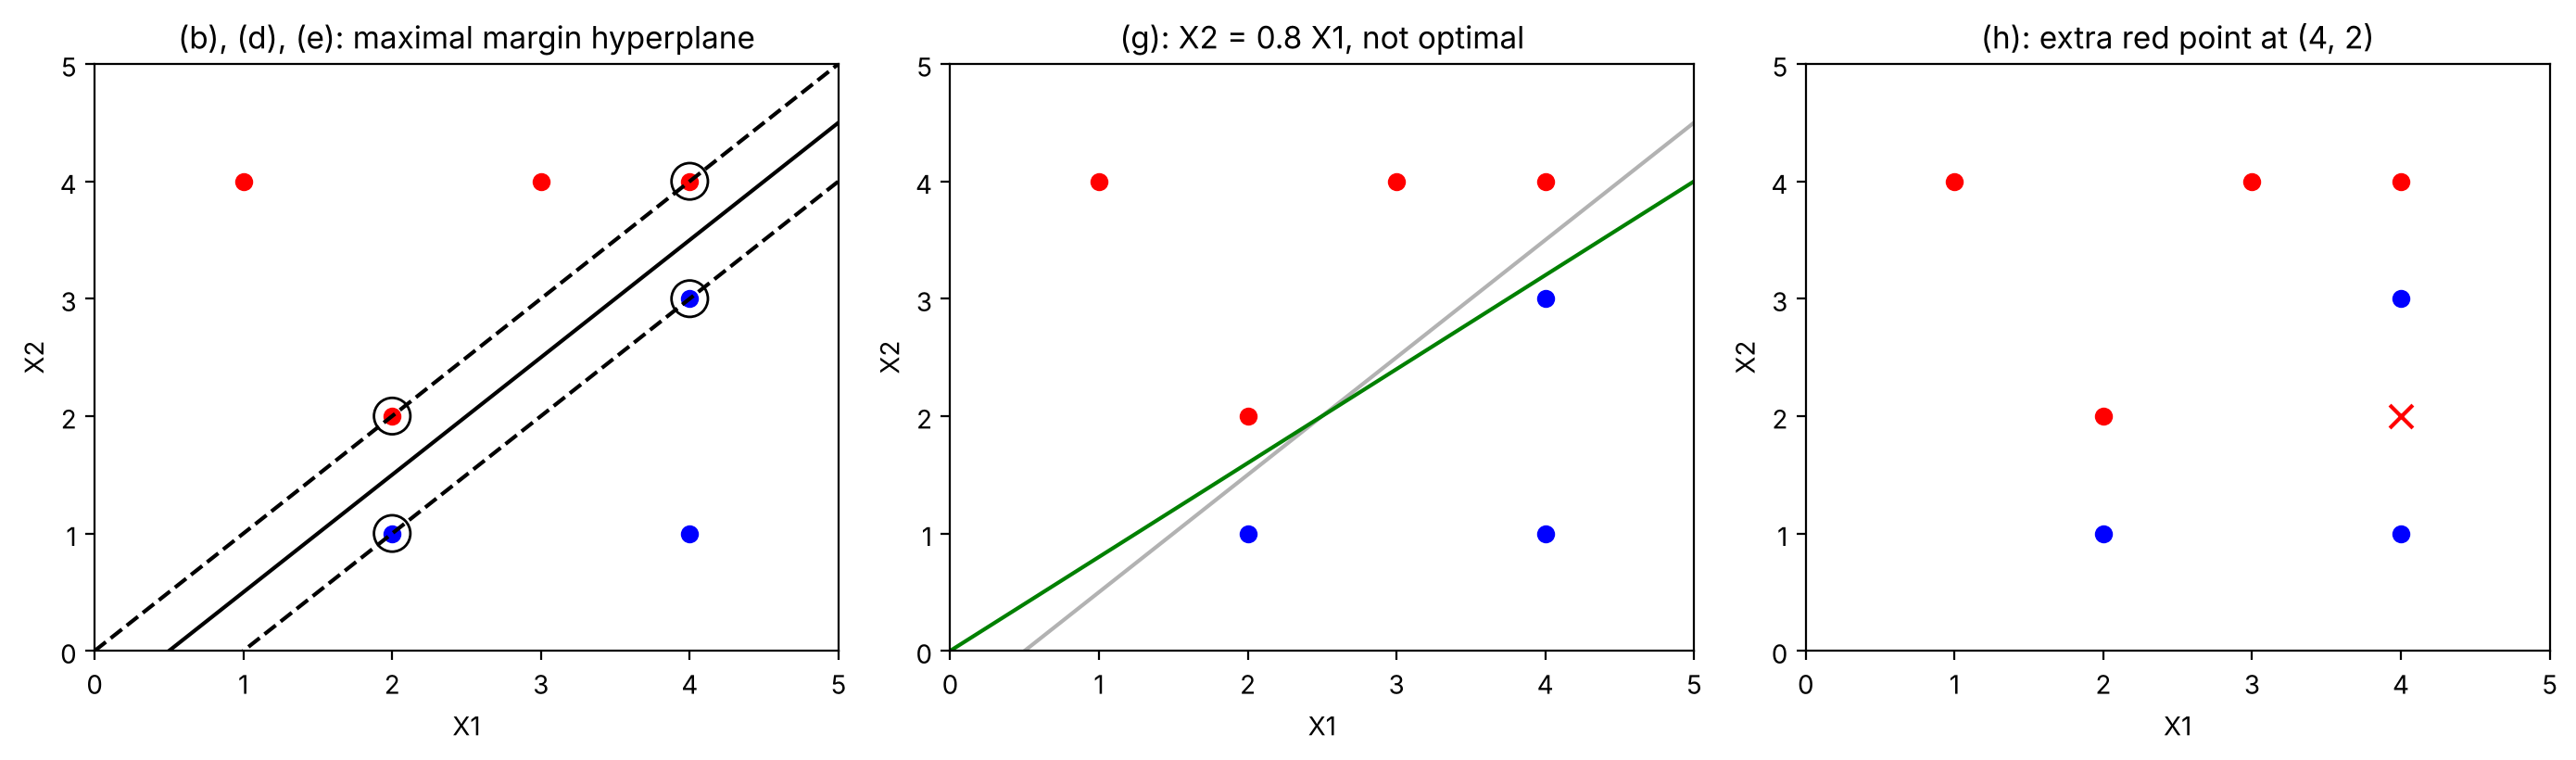

In [19]:
red = np.array([[3, 4], [2, 2], [4, 4], [1, 4]])
blue = np.array([[2, 1], [4, 3], [4, 1]])
xs = np.linspace(0, 5, 10)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax in axes:
    ax.scatter(red[:, 0], red[:, 1], c='red')
    ax.scatter(blue[:, 0], blue[:, 1], c='blue')
    ax.set_xlim(0, 5)
    ax.set_ylim(0, 5)
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')

axes[0].plot(xs, xs - 0.5, 'k')
axes[0].plot(xs, xs, 'k--')
axes[0].plot(xs, xs - 1, 'k--')
sv = np.array([[2, 2], [4, 4], [2, 1], [4, 3]])
axes[0].scatter(sv[:, 0], sv[:, 1], s=200, facecolors='none', edgecolors='k')
axes[0].set_title('(b), (d), (e): maximal margin hyperplane')

axes[1].plot(xs, xs - 0.5, 'k', alpha=0.3)
axes[1].plot(xs, 0.8 * xs, 'g')
axes[1].set_title('(g): X2 = 0.8 X1, not optimal')

axes[2].scatter([4], [2], c='red', marker='x', s=80)
axes[2].set_title('(h): extra red point at (4, 2)')
plt.tight_layout()
plt.show()

(a) Left panel.

(b) The closest opposite-class pairs are (2, 2)/(2, 1) and (4, 4)/(4, 3). The maximal margin hyperplane goes halfway between them, through (2, 1.5) and (4, 3.5): X2 = X1 - 0.5, or 0.5 - X1 + X2 = 0 (solid line).

(c) Classify to Red if 0.5 - X1 + X2 > 0 and to Blue otherwise. β0 = 0.5, β1 = -1, β2 = 1.

(d) The margin edges are the dashed lines X2 = X1 and X2 = X1 - 1. The margin is the distance from the hyperplane to a support vector: |0.5 - 2 + 2| / sqrt(2) = 0.354.

(e) The support vectors are (2, 2), (4, 4), (2, 1) and (4, 3), circled.

(f) The seventh observation (4, 1) is 2.5 / sqrt(2) = 1.77 from the hyperplane, well outside the margin, and is not a support vector. A slight move doesn't change the hyperplane.

(g) Middle panel: X2 = 0.8 X1, or -0.8 X1 + X2 = 0. It separates the classes, but its closest point (4, 3) is only 0.2 / sqrt(1.64) = 0.156 away, smaller than 0.354.

(h) Right panel: add a red observation at (4, 2). Blue (4, 3) is on the segment between red (4, 2) and red (4, 4), so any line with both of those reds on one side also has (4, 3) on that side. The classes are no longer separable.